# LLP vs quantificação — ranks dos métodos

Junta `results_llp_vs_quantification.csv` (baselines do QuaPy + métodos LLP) com
`results_smq_complementar.csv` (SMQ do oráculo + SMQ treinado em LLP) e mostra o
**rank** de cada método em boxplots (1 = melhor).

**Como o rank é calculado.** Um *bloco* de comparação é um cenário
(dataset, regime, tamanho de bag r). Dentro de cada bloco, os métodos são
ordenados pelo erro (menor erro = rank 1; empates recebem o rank médio). Os
métodos do oráculo não dependem das bags, então entram em todos os cenários da
mesma repetição: todos foram avaliados nos mesmos batches de teste.

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

BASE_CSV = "results_llp_vs_quantification.csv"
SMQ_CSV = "results_smq_complementar.csv"

METRICA = "ae_mean"                  # ou "rae_mean"
AGREGAR_REPETICOES = True            # True: média das repetições por dataset antes do rank
                                     #       (blocos = datasets, padrão da literatura)
                                     # False: cada repetição é um bloco
BAG_SIZES_ANALISE = [5, 10, 30, 100] # r=1 é o caso supervisionado (sanity check);
                                     # inclua o 1 aqui se quiser ele nos ranks
SALVAR_FIGURAS = True                # salva cada figura em PNG (300 dpi) nesta pasta

ORDEM_REGIMES = ["iid", "hier"]

GRUPO_LABEL = {"oraculo": "Oráculo (rótulos individuais)",
               "llp": "LLP (métodos do paper)",
               "smq_llp": "SMQ treinado em LLP"}
CORES = {"oraculo": "#b8c0c8", "llp": "#e69f00", "smq_llp": "#0072b2"}

In [18]:
base = pd.read_csv(BASE_CSV)
smq = pd.read_csv(SMQ_CSV)

pareado = smq["pareado"].astype(str).str.lower().eq("true")
print(f"Linhas do SMQ não pareadas (descartadas): {int((~pareado).sum())}")
smq = smq[pareado].drop(columns="pareado")

df = pd.concat([base, smq], ignore_index=True)

print("Pares (dataset, repetição) — base:", base.groupby(["dataset", "repeticao"]).ngroups,
      "| SMQ:", smq.groupby(["dataset", "repeticao"]).ngroups)
print("Linhas por repetição (esperado 132):",
      df.groupby(["dataset", "repeticao"]).size().value_counts().to_dict())
print("Métodos por grupo:")
for g, ms in df.groupby("grupo")["metodo"].unique().items():
    print(f"  {g}: {sorted(ms)}")

Linhas do SMQ não pareadas (descartadas): 0
Pares (dataset, repetição) — base: 900 | SMQ: 900
Linhas por repetição (esperado 132): {132: 900}
Métodos por grupo:
  llp: ['LLP_AlterSVM_CC', 'LLP_EPRM_CC', 'LLP_EPRM_PCC', 'LLP_InvCal_CC', 'LLP_InvCal_PCC', 'LLP_MeanMap_CC', 'LLP_MeanMap_PCC']
  oraculo: ['ACC', 'CC', 'DyS', 'EMQ', 'KDEyML', 'PACC', 'PCC', 'smq_base', 'smq_et', 'smq_gbr', 'smq_iso', 'smq_rf']
  smq_llp: ['smq_llp_base', 'smq_llp_et', 'smq_llp_gbr', 'smq_llp_iso', 'smq_llp_rf']


## Funções

In [19]:
def montar_cenarios(df, metrica=METRICA, bag_sizes=BAG_SIZES_ANALISE):
    # Uma linha por (dataset, repetição, regime, r, método). O oráculo é
    # replicado em todos os cenários (regime, r) da mesma repetição.
    llp = df[(df["regime"] != "oraculo") & df["bag_size"].isin(bag_sizes)]
    orac = df[df["regime"] == "oraculo"].drop(columns=["regime", "bag_size"])
    cenarios = llp[["dataset", "repeticao", "regime", "bag_size"]].drop_duplicates()
    orac = cenarios.merge(orac, on=["dataset", "repeticao"])
    cols = ["dataset", "repeticao", "regime", "bag_size", "grupo", "metodo", metrica]
    return pd.concat([llp[cols], orac[cols]], ignore_index=True)


def calcular_ranks(cen, metrica=METRICA, agregar=AGREGAR_REPETICOES, grupos=None):
    # Rank por bloco (1 = menor erro). Retorna formato longo: bloco, metodo, rank, grupo.
    if grupos is not None:
        cen = cen[cen["grupo"].isin(grupos)]
    bloco = ["dataset", "regime", "bag_size"] + ([] if agregar else ["repeticao"])
    largo = cen.pivot_table(index=bloco, columns="metodo", values=metrica, aggfunc="mean")
    incompletos = int(largo.isna().any(axis=1).sum())
    if incompletos:
        print(f"⚠️  {incompletos} blocos com método faltando foram descartados:")
        print(largo.isna().sum()[lambda s: s > 0].to_string())
    largo = largo.dropna()
    ranks = largo.rank(axis=1, method="average", ascending=True)
    longo = ranks.reset_index().melt(id_vars=bloco, var_name="metodo", value_name="rank")
    grupo_do_metodo = cen.drop_duplicates("metodo").set_index("metodo")["grupo"]
    longo["grupo"] = longo["metodo"].map(grupo_do_metodo)
    print(f"Blocos: {len(largo)} | métodos: {largo.shape[1]}")
    return longo


def boxplot_ranks(longo, titulo, ax=None, arquivo=None):
    medias = longo.groupby("metodo")["rank"].mean().sort_values()
    metodos = list(medias.index)
    grupos = longo.drop_duplicates("metodo").set_index("metodo")["grupo"]
    dados = [longo.loc[longo["metodo"] == m, "rank"].values for m in metodos]

    fig = None
    if ax is None:
        fig, ax = plt.subplots(figsize=(8, 0.32 * len(metodos) + 1.8))
    kw = dict(patch_artist=True, widths=0.6, showmeans=True,
              meanprops=dict(marker="D", markerfacecolor="white",
                             markeredgecolor="black", markersize=4),
              medianprops=dict(color="black", linewidth=1.2),
              flierprops=dict(marker=".", markersize=3, alpha=0.4))
    try:
        bp = ax.boxplot(dados, orientation="horizontal", **kw)   # matplotlib >= 3.10
    except TypeError:
        bp = ax.boxplot(dados, vert=False, **kw)                 # versões anteriores
    for caixa, m in zip(bp["boxes"], metodos):
        caixa.set_facecolor(CORES.get(grupos[m], "white"))

    ax.set_yticks(range(1, len(metodos) + 1))
    ax.set_yticklabels([f"{m}  ({medias[m]:.2f})" for m in metodos], fontsize=8)
    ax.invert_yaxis()                       # melhor rank médio no topo
    ax.set_xlabel("rank (1 = melhor)  —  ◇ = média, | = mediana")
    ax.set_xlim(0.5, len(metodos) + 0.5)
    ax.grid(axis="x", alpha=0.3)
    ax.set_title(titulo, fontsize=10)
    presentes = [g for g in CORES if g in set(grupos[metodos])]
    ax.legend(handles=[Patch(facecolor=CORES[g], edgecolor="black", label=GRUPO_LABEL[g])
                       for g in presentes],
              loc="upper right", fontsize=8, framealpha=0.9)
    if fig is not None:
        fig.tight_layout()
        if SALVAR_FIGURAS and arquivo:
            fig.savefig(arquivo, dpi=300, bbox_inches="tight")
        plt.show()
    return ax


def heatmap_rank_medio(longo, titulo, arquivo=None):
    tab = longo.pivot_table(index="metodo", columns=["regime", "bag_size"],
                            values="rank", aggfunc="mean")
    tab = tab.loc[tab.mean(axis=1).sort_values().index]
    tab = tab[sorted(tab.columns, key=lambda c: (ORDEM_REGIMES.index(c[0])
                                                 if c[0] in ORDEM_REGIMES else 99, c[1]))]
    fig, ax = plt.subplots(figsize=(0.9 * tab.shape[1] + 3.5, 0.32 * tab.shape[0] + 1.5))
    im = ax.imshow(tab.values, cmap="RdYlGn_r", aspect="auto")
    ax.set_xticks(range(tab.shape[1]))
    ax.set_xticklabels([f"{reg}\nr={int(r)}" for reg, r in tab.columns], fontsize=8)
    ax.set_yticks(range(tab.shape[0]))
    ax.set_yticklabels(tab.index, fontsize=8)
    for i in range(tab.shape[0]):
        for j in range(tab.shape[1]):
            ax.text(j, i, f"{tab.values[i, j]:.1f}", ha="center", va="center", fontsize=7)
    fig.colorbar(im, ax=ax, label="rank médio (menor = melhor)")
    ax.set_title(titulo, fontsize=10)
    fig.tight_layout()
    if SALVAR_FIGURAS and arquivo:
        fig.savefig(arquivo, dpi=300, bbox_inches="tight")
    plt.show()

## 1. Todos os métodos (oráculo + LLP + SMQ em LLP)

O oráculo vê o rótulo de cada instância, então é esperado que ele domine.
Este gráfico mostra **o quanto se perde** ao treinar só com proporções.

Blocos: 240 | métodos: 24


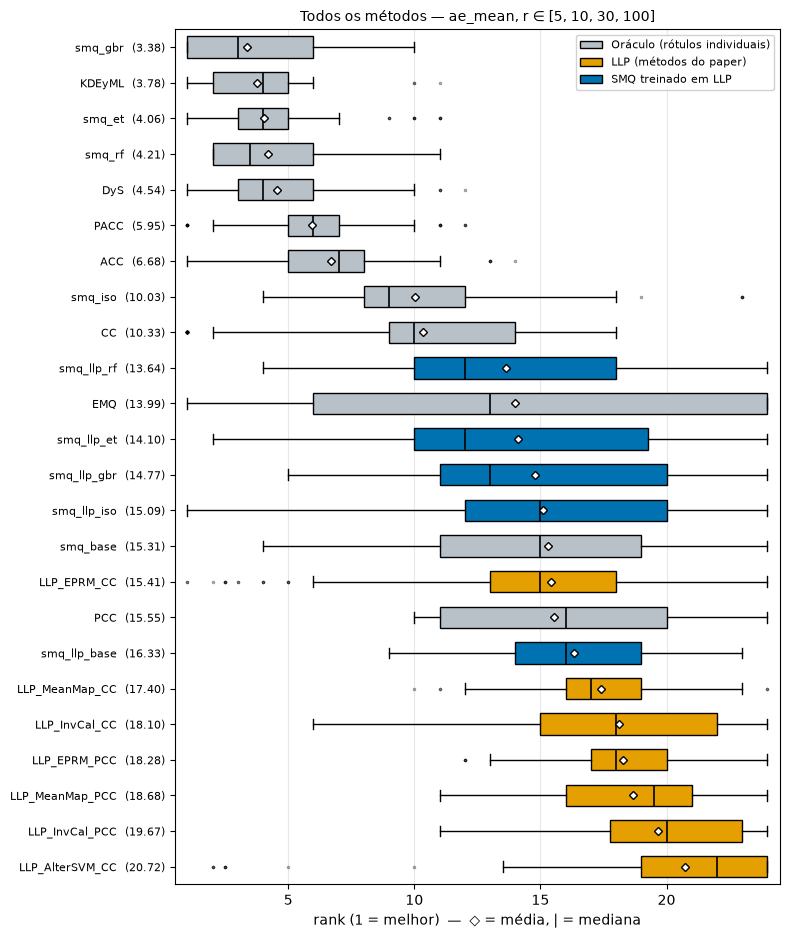

<Axes: title={'center': 'Todos os métodos — ae_mean, r ∈ [5, 10, 30, 100]'}, xlabel='rank (1 = melhor)  —  ◇ = média, | = mediana'>

In [20]:
cen = montar_cenarios(df)
r_todos = calcular_ranks(cen)
boxplot_ranks(r_todos, f"Todos os métodos — {METRICA}, r ∈ {BAG_SIZES_ANALISE}",
              arquivo=f"rank_todos_{METRICA}.png")

## 2. Só métodos que treinam com proporções (LLP + SMQ em LLP)

A comparação justa entre o SMQ treinado em LLP e os métodos do paper: todos
veem exatamente a mesma informação (bags + proporções).

Blocos: 240 | métodos: 12


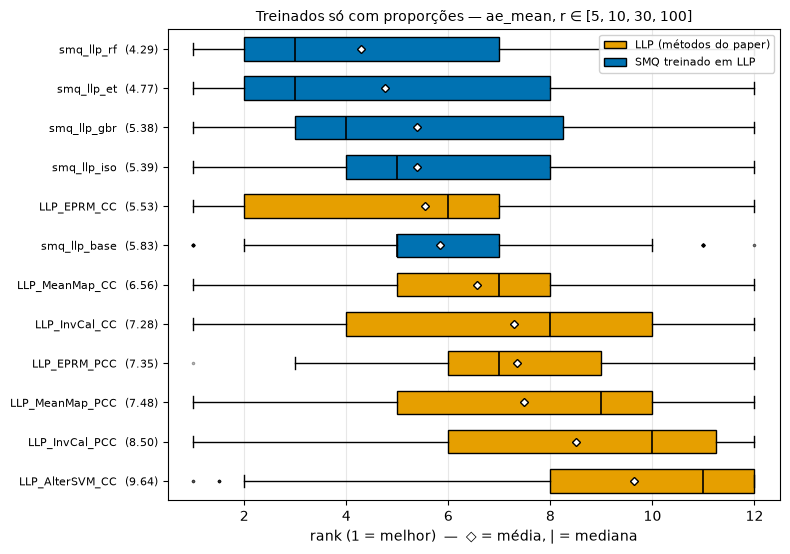

<Axes: title={'center': 'Treinados só com proporções — ae_mean, r ∈ [5, 10, 30, 100]'}, xlabel='rank (1 = melhor)  —  ◇ = média, | = mediana'>

In [21]:
r_llp = calcular_ranks(cen, grupos=["llp", "smq_llp"])
boxplot_ranks(r_llp, f"Treinados só com proporções — {METRICA}, r ∈ {BAG_SIZES_ANALISE}",
              arquivo=f"rank_llp_{METRICA}.png")

## 3. Separado por regime de bags

`iid`: proporções das bags concentradas no prior (caso difícil, Lema 2 do paper).
`hier`: cada bag com seu próprio prior (proporções variadas).

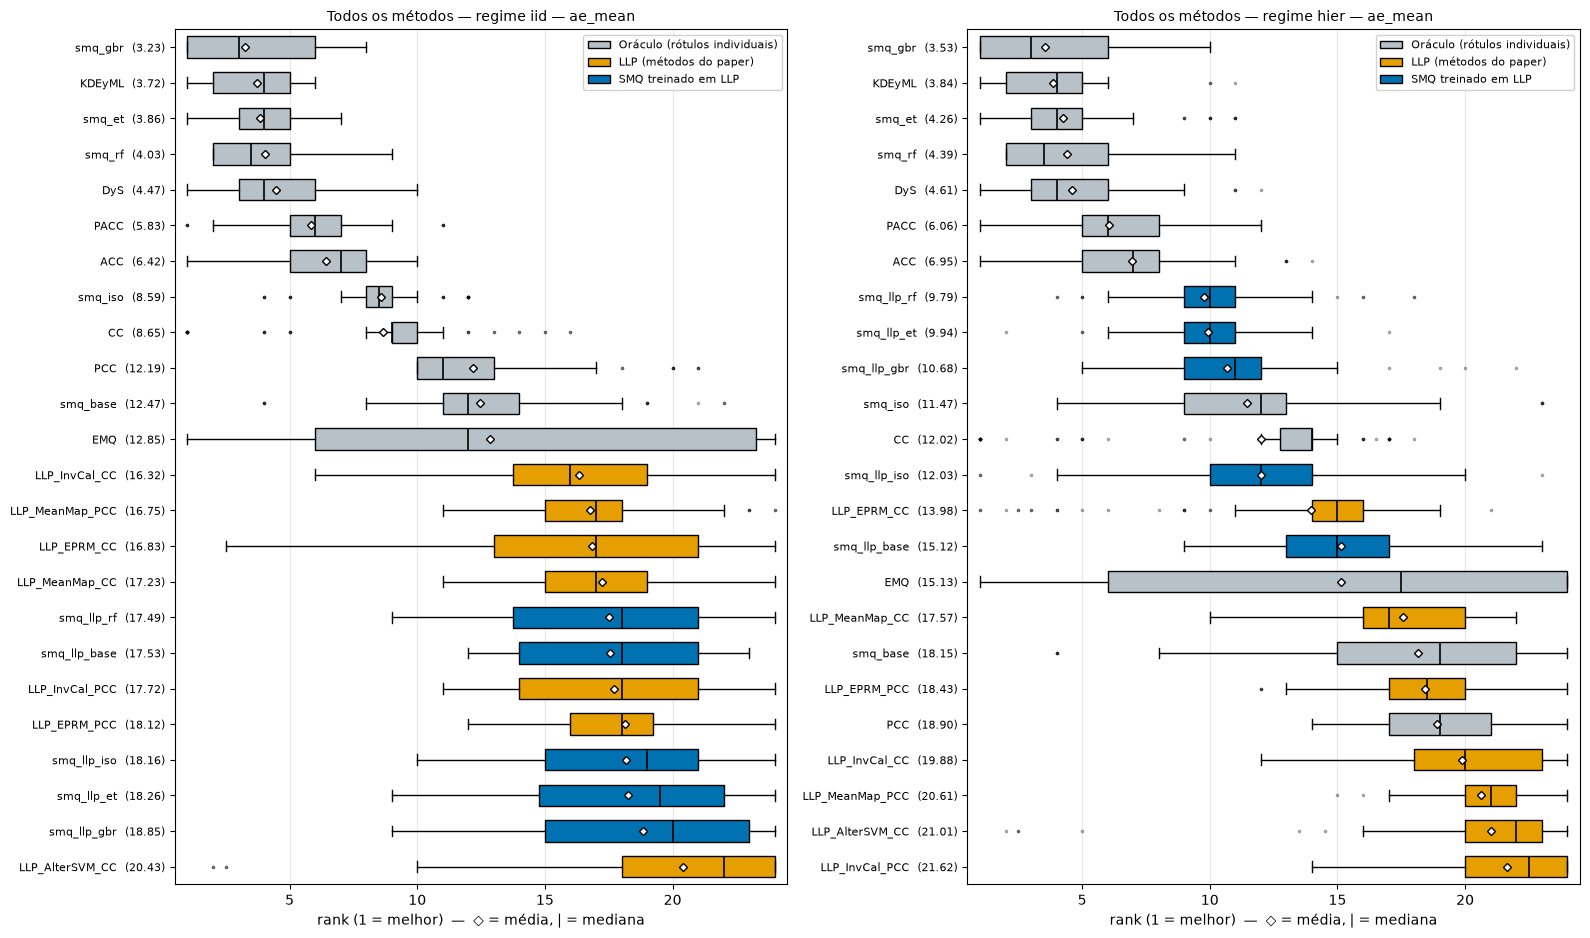

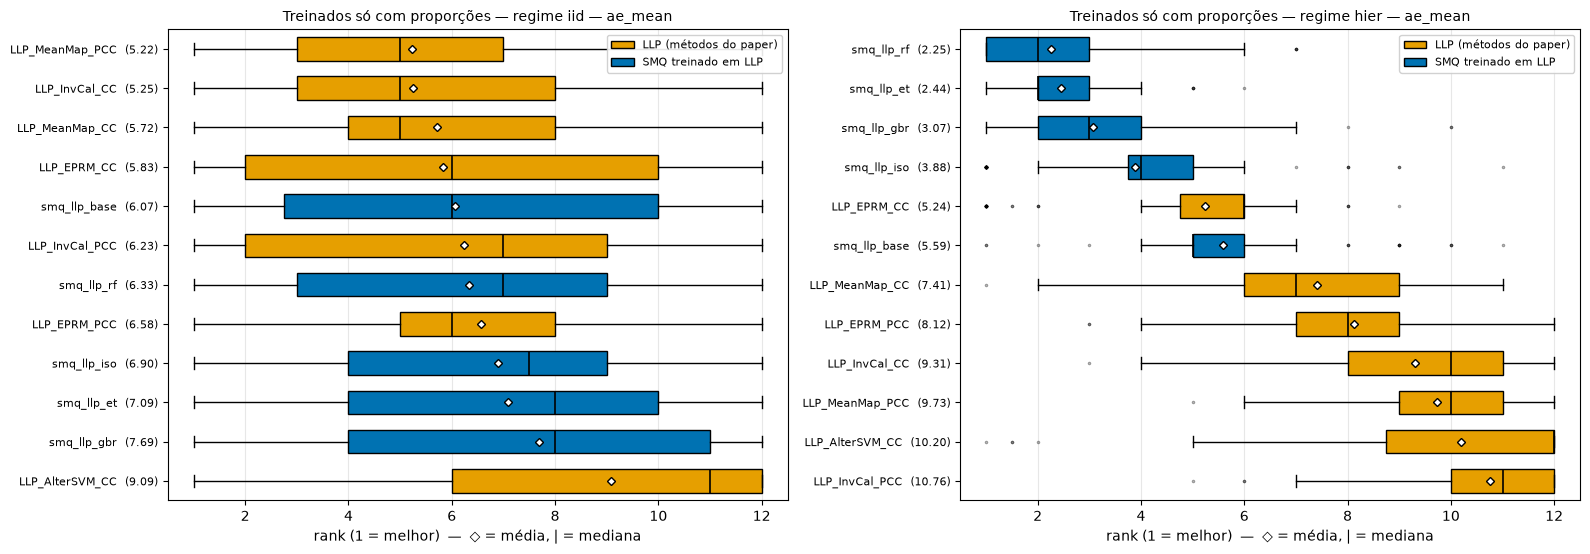

In [22]:
for titulo, nome, longo in [("Todos os métodos", "todos", r_todos),
                            ("Treinados só com proporções", "llp", r_llp)]:
    regimes = [r for r in ORDEM_REGIMES if r in set(longo["regime"])]
    n_met = longo["metodo"].nunique()
    fig, axes = plt.subplots(1, len(regimes), figsize=(8 * len(regimes), 0.32 * n_met + 1.8))
    for ax, reg in zip(np.atleast_1d(axes), regimes):
        boxplot_ranks(longo[longo["regime"] == reg], f"{titulo} — regime {reg} — {METRICA}", ax=ax)
    fig.tight_layout()
    if SALVAR_FIGURAS:
        fig.savefig(f"rank_{nome}_por_regime_{METRICA}.png", dpi=300, bbox_inches="tight")
    plt.show()

## 4. Rank médio por regime e tamanho de bag

Resume onde cada método ganha ou perde: em geral os métodos LLP pioram com r
grande no regime `iid`, onde as proporções quase não variam entre bags.

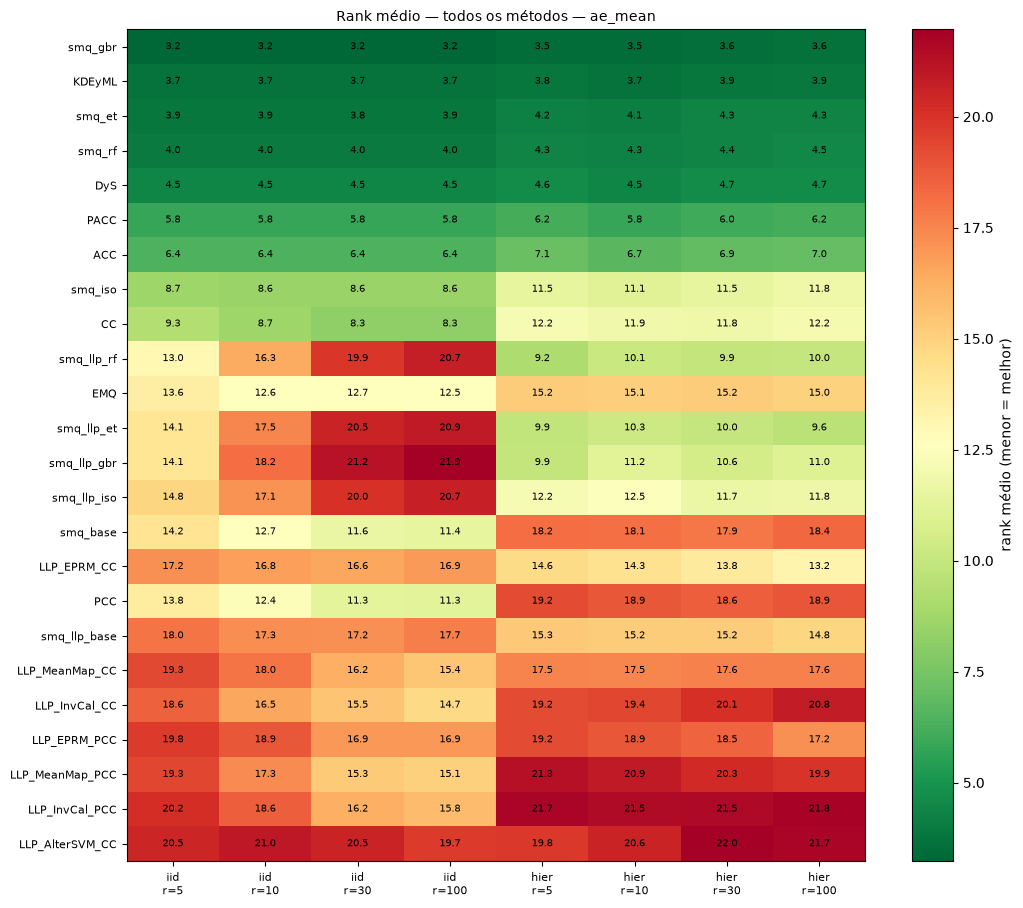

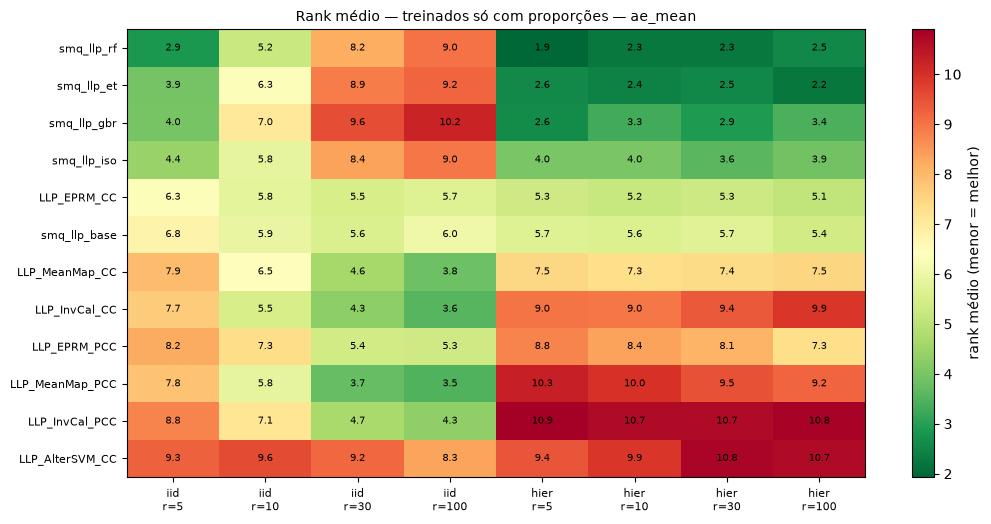

In [23]:
heatmap_rank_medio(r_todos, f"Rank médio — todos os métodos — {METRICA}",
                   arquivo=f"heatmap_todos_{METRICA}.png")
heatmap_rank_medio(r_llp, f"Rank médio — treinados só com proporções — {METRICA}",
                   arquivo=f"heatmap_llp_{METRICA}.png")

## 5. Tabela de ranks médios

In [24]:
tabela = (r_todos.groupby(["grupo", "metodo"])["rank"]
          .agg(rank_medio="mean", rank_mediano="median")
          .sort_values("rank_medio").round(2))
erro = (cen.groupby("metodo")[METRICA].agg(["mean", "std"])
        .rename(columns={"mean": f"{METRICA}_medio", "std": f"{METRICA}_desvio"}))
tabela.join(erro, on="metodo").round(4)

rank_medio  rank_mediano  ae_mean_medio  \
grupo   metodo                                                     
oraculo smq_gbr                3.38           3.0         0.0406   
        KDEyML                 3.78           4.0         0.0443   
        smq_et                 4.06           4.0         0.0415   
        smq_rf                 4.21           3.5         0.0411   
        DyS                    4.54           4.0         0.0447   
        PACC                   5.95           6.0         0.0467   
        ACC                    6.68           7.0         0.0531   
        smq_iso               10.03           9.0         0.0688   
        CC                    10.33          10.0         0.0905   
smq_llp smq_llp_rf            13.64          12.0         0.1330   
oraculo EMQ                   13.99          13.0         0.1706   
smq_llp smq_llp_et            14.10          12.0         0.1334   
        smq_llp_gbr           14.77          13.0         0.1350   
        smq_llp_iso           15.09          15.0         0.1356   
oraculo smq_base              15.31          15.0         0.1213   
llp     LLP_EPRM_CC           15.41          15.0         0.1440   
oraculo PCC                   15.55          16.0         0.1158   
smq_llp smq_llp_base          16.33          16.0         0.1414   
llp     LLP_MeanMap_CC        17.40          17.0         0.1452   
        LLP_InvCal_CC         18.10          18.0         0.1534   
        LLP_EPRM_PCC          18.28          18.0         0.1503   
        LLP_MeanMap_PCC       18.68          19.5         0.1494   
        LLP_InvCal_PCC        19.67          20.0         0.1646   
        LLP_AlterSVM_CC       20.72          22.0         0.2102   

                         ae_mean_desvio  
grupo   metodo                           
oraculo smq_gbr                  0.0474  
        KDEyML                   0.0531  
        smq_et                   0.0489  
        smq_rf                   0.0475  
        DyS                      0.0532  
        PACC                     0.0485  
        ACC                      0.0591  
        smq_iso                  0.0740  
        CC                       0.0709  
smq_llp smq_llp_rf               0.1081  
oraculo EMQ                      0.1802  
smq_llp smq_llp_et               0.1080  
        smq_llp_gbr              0.1094  
        smq_llp_iso              0.1086  
oraculo smq_base                 0.0993  
llp     LLP_EPRM_CC              0.1206  
oraculo PCC                      0.0761  
smq_llp smq_llp_base             0.1107  
llp     LLP_MeanMap_CC           0.0997  
        LLP_InvCal_CC            0.0984  
        LLP_EPRM_PCC             0.0849  
        LLP_MeanMap_PCC          0.0867  
        LLP_InvCal_PCC           0.0717  
        LLP_AlterSVM_CC          0.1524